<a href="https://colab.research.google.com/github/SebGalvaleira/mineria-datos-ii-parcial/blob/main/notebooks/e2/E2_07_analitica_anomalias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E2_07 · Analítica: detección de anomalías de costo

**Dónde estamos:** Gold → **Analítica**. El mart `org_daily_usage_by_service` está validado y publicado en AstraDB. Ahora respondemos la pregunta de FinOps *"¿qué costos son anómalos?"* con un método estadístico justificado, no solo con la regla fija de Silver.

**Punto de partida:** en Silver, un evento es *pico* si cuesta más de 5 × p99 (83,59 USD), un umbral único para todos los servicios. Comparamos tres métodos sobre el costo diario de cada serie org × servicio:
- **z-score clásico:** (costo − media) / desvío. Simple, pero los propios picos inflan la media y el desvío (enmascaramiento).
- **Percentil 99 por servicio:** marca el 1 % más caro de cada servicio, haya o no anomalías.
- **z robusto con MAD:** 0,6745 × (costo − mediana) / MAD. La mediana y el MAD casi no se mueven con los picos, y cada serie se compara contra sí misma.

In [2]:
!pip install -q "pyspark>=4.0,<4.1"
import os, shutil, subprocess
os.environ.pop('JAVA_HOME', None)

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
LAKE_DRIVE = Path('/content/drive/MyDrive/cpa_datalake')   # respaldo persistente
LAKE       = Path('/content/cpa_datalake')                  # copia de trabajo (disco local de Colab)

RUTAS = {z: LAKE / z for z in ['landing', 'stream_input', 'bronze', 'silver',
                               'gold', 'quarantine', 'checkpoints', 'logs']}

def restaurar(*rutas):
    """Copia desde Drive SOLO las carpetas que este notebook necesita (si no están ya en local)."""
    for r in rutas:
        origen, destino = LAKE_DRIVE / r, LAKE / r
        if origen.exists() and not destino.exists():
            shutil.copytree(origen, destino)
            print('✓ restaurado:', r)

def guardar_en_drive(*rutas):
    """Sincroniza en Drive SOLO las carpetas indicadas."""
    for r in rutas:
        origen, destino = LAKE / r, LAKE_DRIVE / r
        destino.mkdir(parents=True, exist_ok=True)
        subprocess.run(['rsync', '-a', '--delete', f'{origen}/', f'{destino}/'], check=True)
        print('✓ sincronizado:', r)

from pyspark.sql import SparkSession, functions as F, types as T
spark = (SparkSession.builder.appName('cloud-provider-analytics')
         .config('spark.sql.session.timeZone', 'UTC')
         .config('spark.sql.shuffle.partitions', '8')
         .config('spark.sql.sources.partitionOverwriteMode', 'dynamic')
         .getOrCreate())
print('Spark', spark.version)

Mounted at /content/drive
Spark 4.0.5


In [3]:
# solo necesitamos gold (de donde leemos y donde escribimos el mart nuevo) y logs (evidencia)
import json
import pandas as pd
import matplotlib.pyplot as plt
restaurar('gold', 'logs')
for p in RUTAS.values():
    p.mkdir(parents=True, exist_ok=True)

✓ restaurado: gold
✓ restaurado: logs


In [4]:
# perfil por servicio

# antes de elegir un método, mirar los datos: cada servicio vive en una escala distinta
gold = spark.read.parquet(str(RUTAS['gold'] / 'org_daily_usage_by_service'))
base = (gold.select('org_id', 'event_date', 'service', 'industry', 'plan_tier', 'eventos',
                    F.col('daily_cost_usd').alias('costo'),
                    (F.col('eventos_pico') > 0).alias('regla_pico'),
                    (F.col('eventos_costo_anomalo') > 0).alias('regla_negativo'))
            .cache())
perfil = (base.groupBy('service')
              .agg(F.count('*').alias('filas'),
                   F.round(F.median('costo'), 2).alias('mediana'),
                   F.round(F.percentile('costo', 0.99), 2).alias('p99'),
                   F.round(F.max('costo'), 2).alias('maximo'),
                   F.sum(F.col('regla_pico').cast('int')).alias('picos_regla'))
              .withColumn('max_sobre_mediana', F.round(F.col('maximo') / F.col('mediana'), 1))
              .orderBy('service').toPandas())
display(perfil)

,service,filas,mediana,p99,maximo,picos_regla,max_sobre_mediana
0,analytics,1289,13.29,47.46,257.04,8,19.3
1,compute,2839,18.34,87.14,311.26,26,17.0
2,database,1919,10.62,42.83,150.59,10,14.2
3,genai,1131,21.83,79.80,340.53,5,15.6
4,networking,1955,1.92,7.05,31.92,0,16.6
5,storage,1917,4.31,17.14,72.00,0,16.7


In [5]:
# los 3 scores
# cada serie org x servicio se compara contra su propia historia (262 series, 24 a 60 días cada una)
# MAD = mediana de |costo - mediana|. 0.6745 lo pone en la misma escala que un z-score normal
UMBRAL_MAD = 5       # z robusto > 5 (justificado con la tabla de sensibilidad de la celda 6)
MIN_DIAS   = 14      # una serie con menos historia no se puntúa (mediana poco confiable)
SERIE      = ['org_id', 'service']

stats = base.groupBy(SERIE).agg(F.count('*').alias('dias'), F.mean('costo').alias('media'),
                                F.stddev('costo').alias('desvio'), F.median('costo').alias('mediana'))
con_stats = base.join(stats, SERIE).withColumn('desvio_abs', F.abs(F.col('costo') - F.col('mediana')))
mad = con_stats.groupBy(SERIE).agg(F.median('desvio_abs').alias('mad'))
p99_servicio = base.groupBy('service').agg(F.percentile('costo', 0.99).alias('p99_servicio'))

si = lambda cond: F.coalesce(cond, F.lit(False))      # null (p. ej. MAD = 0) cuenta como "no marcado"
scores = (con_stats.join(mad, SERIE).join(F.broadcast(p99_servicio), 'service')
    .withColumn('z', (F.col('costo') - F.col('media')) / F.col('desvio'))
    .withColumn('z_robusto', F.when(F.col('mad') > 0, 0.6745 * (F.col('costo') - F.col('mediana')) / F.col('mad')))
    .withColumn('m_zscore', si(F.col('z') > 3))
    .withColumn('m_p99',    si(F.col('costo') > F.col('p99_servicio')))
    .withColumn('m_mad',    si((F.col('z_robusto') > UMBRAL_MAD) & (F.col('dias') >= MIN_DIAS)))
    .cache())
print('Series org x servicio:', stats.count(), '· días por serie: min', stats.agg(F.min('dias')).first()[0],
      '· filas puntuadas:', scores.count())

Series org x servicio: 262 · días por serie: min 24 · filas puntuadas: 11050


In [6]:
#comparacion de metodos y sensibiliad del umbral

# la regla de silver no es "la verdad", pero sus 49 picos son anomalías seguras: un buen método tiene que encontrarlas todas
# "nuevas" = lo que el método marca y la regla no. hay que revisarlas, no son errores automáticamente
TOTAL_PICOS = base.filter('regla_pico').count()
def evaluar(nombre, cond):
    r = scores.agg(F.sum(cond.cast('int')).alias('marcados'),
                   F.sum((cond & F.col('regla_pico')).cast('int')).alias('coinciden_con_regla'),
                   F.sum((cond & ~F.col('regla_pico')).cast('int')).alias('nuevas'),
                   F.sum((~cond & F.col('regla_pico')).cast('int')).alias('picos_perdidos')).first().asDict()
    return {'metodo': nombre, **r, 'recall_vs_regla': round(r['coinciden_con_regla'] / TOTAL_PICOS, 2)}

comparacion = pd.DataFrame([
    evaluar('z-score clásico > 3 (por serie)', F.col('m_zscore')),
    evaluar('percentil 99 (por servicio)',     F.col('m_p99')),
    *[evaluar(f'MAD z robusto > {u} (por serie)',
              si((F.col('z_robusto') > u) & (F.col('dias') >= MIN_DIAS))) for u in [3.5, 5, 7, 10]]])
print('Picos de la regla (eventos > 5 x p99 en Silver):', TOTAL_PICOS)
display(comparacion)

Picos de la regla (eventos > 5 x p99 en Silver): 49


,metodo,marcados,coinciden_con_regla,nuevas,picos_perdidos,recall_vs_regla
0,z-score clásico > 3 (por serie),93,49,44,0,1.00
1,percentil 99 (por servicio),114,49,65,0,1.00
2,MAD z robusto > 3.5 (por serie),124,49,75,0,1.00
3,MAD z robusto > 5 (por serie),82,49,33,0,1.00
4,MAD z robusto > 7 (por serie),75,49,26,0,1.00
5,MAD z robusto > 10 (por serie),72,48,24,1,0.98


In [7]:
# que son las 33 nuevas?

nuevas = scores.filter('m_mad AND NOT regla_pico')
display(nuevas.groupBy('service').count().orderBy(F.desc('count')).toPandas())
display(nuevas.select('org_id', 'event_date', 'service', 'eventos', F.round('costo', 2).alias('costo'),
                      F.round('mediana', 2).alias('mediana_serie'),
                      F.round(F.col('costo') / F.col('mediana'), 1).alias('veces_mediana'),
                      F.round('z_robusto', 1).alias('z_robusto'))
              .orderBy(F.desc('z_robusto')).limit(10).toPandas())

,service,count
0,storage,15
1,networking,13
2,analytics,2
3,compute,2
4,database,1


,org_id,event_date,service,eventos,costo,mediana_serie,veces_mediana,z_robusto
0,org_w3zp08j3,2025-07-05,networking,3,27.42,1.48,18.5,35.4
1,org_w3zp08j3,2025-07-16,networking,3,26.42,1.48,17.8,34.0
2,org_874frhoc,2025-07-17,networking,3,27.65,1.71,16.2,28.9
3,org_pnsm43d8,2025-07-17,storage,3,56.67,3.58,15.8,27.7
4,org_y9v86wzs,2025-07-08,networking,3,21.82,1.55,14.1,22.5
5,org_5935a0l7,2025-08-26,networking,6,27.97,2.07,13.5,21.3
6,org_cwi64ciy,2025-08-23,networking,3,27.21,1.48,18.3,21.2
7,org_c11ertj5,2025-08-27,storage,3,50.53,3.59,14.1,20.9
8,org_41ibljh7,2025-08-12,networking,3,19.39,1.39,13.9,20.7
9,org_874frhoc,2025-07-29,storage,3,50.18,3.54,14.2,19.7


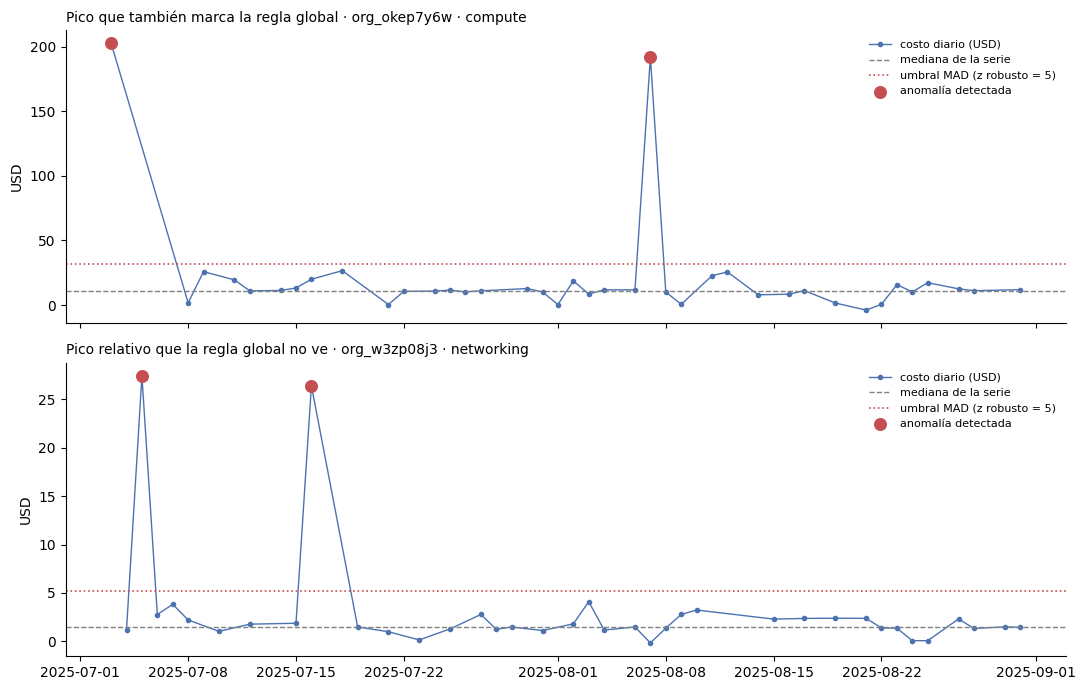

In [8]:
# grafico
def serie_pd(org, servicio):
    return (scores.filter((F.col('org_id') == org) & (F.col('service') == servicio))
                  .select('event_date', 'costo', 'mediana', 'mad', 'm_mad', 'regla_pico')
                  .orderBy('event_date').toPandas())

ej_nueva = nuevas.orderBy(F.desc('z_robusto')).first()
ej_pico  = scores.filter('regla_pico').orderBy(F.desc('z_robusto')).first()
fig, ejes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for eje, ej, titulo in [(ejes[0], ej_pico, 'Pico que también marca la regla global'),
                        (ejes[1], ej_nueva, 'Pico relativo que la regla global no ve')]:
    s = serie_pd(ej['org_id'], ej['service'])
    umbral = s.mediana.iloc[0] + UMBRAL_MAD * s.mad.iloc[0] / 0.6745
    eje.plot(s.event_date, s.costo, marker='o', ms=3, lw=1, color='#4c72b0', label='costo diario (USD)')
    eje.axhline(s.mediana.iloc[0], ls='--', color='gray', lw=1, label='mediana de la serie')
    eje.axhline(umbral, ls=':', color='#c44e52', lw=1.2, label=f'umbral MAD (z robusto = {UMBRAL_MAD})')
    m = s[s.m_mad]
    eje.scatter(m.event_date, m.costo, s=70, color='#c44e52', zorder=3, label='anomalía detectada')
    eje.set_title(f"{titulo} · {ej['org_id']} · {ej['service']}", fontsize=10, loc='left')
    eje.set_ylabel('USD'); eje.legend(fontsize=8, loc='upper right', frameon=False)
    eje.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(RUTAS['logs'] / 'anomalias_ejemplos.png', dpi=120)
plt.show()

In [9]:
# mart "cost_anomaly_mart" en gold

# es el mart que diseñamos en la entrega 1: una fila por org x día x servicio con anomalía y su motivo
motivo = F.concat_ws(' + ', F.array_compact(F.array(
    F.when(F.col('regla_pico'), F.lit('pico_regla_global')),
    F.when(F.col('m_mad'), F.lit('pico_relativo_serie')),
    F.when(F.col('regla_negativo'), F.lit('costo_negativo')))))
mart = (scores.filter('regla_pico OR m_mad OR regla_negativo')
              .select('org_id', 'event_date', 'service', 'industry', 'plan_tier', 'eventos',
                      F.round('costo', 4).alias('daily_cost_usd'),
                      F.round('mediana', 4).alias('mediana_serie'), F.round('mad', 4).alias('mad_serie'),
                      F.round('z_robusto', 2).alias('z_robusto'),
                      F.col('regla_pico'), F.col('m_mad').alias('pico_relativo'), F.col('regla_negativo'),
                      motivo.alias('motivo'),
                      F.current_timestamp().alias('updated_at')))
GOLD_ANOM = RUTAS['gold'] / 'cost_anomaly_mart'
mart.repartition('event_date').write.mode('overwrite').partitionBy('event_date').parquet(str(GOLD_ANOM))
resumen_motivos = spark.read.parquet(str(GOLD_ANOM)).groupBy('motivo').count().orderBy(F.desc('count')).toPandas()
display(resumen_motivos)

,motivo,count
0,costo_negativo,207
1,pico_regla_global + pico_relativo_serie,48
2,pico_relativo_serie,33
3,pico_regla_global + pico_relativo_serie + cost...,1


In [10]:
#evidencia

comparacion.to_csv(RUTAS['logs'] / 'anomalias_comparacion_metodos.csv', index=False)
json.dump({'metodo_elegido': 'MAD z robusto por serie org x servicio', 'umbral_z_robusto': UMBRAL_MAD,
           'min_dias_serie': MIN_DIAS, 'picos_regla': TOTAL_PICOS,
           'marcados_mad': int(scores.filter('m_mad').count()),
           'nuevas_mad': int(nuevas.count()),
           'filas_cost_anomaly_mart': int(resumen_motivos['count'].sum()),
           'motivos': dict(zip(resumen_motivos.motivo, resumen_motivos['count'].astype(int)))},
          open(RUTAS['logs'] / 'anomalias_resumen.json', 'w'), indent=2)
guardar_en_drive('gold', 'logs')
print(open(RUTAS['logs'] / 'anomalias_resumen.json').read())

✓ sincronizado: gold
✓ sincronizado: logs
{
  "metodo_elegido": "MAD z robusto por serie org x servicio",
  "umbral_z_robusto": 5,
  "min_dias_serie": 14,
  "picos_regla": 49,
  "marcados_mad": 82,
  "nuevas_mad": 33,
  "filas_cost_anomaly_mart": 289,
  "motivos": {
    "costo_negativo": 207,
    "pico_regla_global + pico_relativo_serie": 48,
    "pico_relativo_serie": 33,
    "pico_regla_global + pico_relativo_serie + costo_negativo": 1
  }
}


## Cierre: detección de anomalías de costo

**Dónde estamos:** Gold → Analítica. Ahora Gold tiene un segundo mart, `cost_anomaly_mart` (289 filas), que responde *"¿qué costos son anómalos y por qué?"*.

**Qué hicimos:** comparamos tres métodos sobre el costo diario de 262 series org × servicio, usando como referencia los 49 picos de la regla de Silver (evento > 5 × p99 = 83,59 USD).

| Método | Marcados | Picos de la regla encontrados | Nuevas | Problema |
|---|---|---|---|---|
| z-score > 3 | 93 | 49/49 | 44 | Los picos inflan la media y el desvío (enmascaramiento) |
| p99 por servicio | 114 | 49/49 | 65 | Siempre marca el 1 %, haya o no anomalías |
| **MAD z robusto > 5** | **82** | **49/49** | **33** | **Elegido** |

**Por qué MAD (y no ML):** la mediana y el MAD casi no se mueven con los picos, cada serie se compara contra su propia escala, el resultado es explicable ("18 veces su mediana") y no necesita etiquetas. Con 60 días de historia y sin anomalías etiquetadas, un modelo supervisado no se justifica (la consigna pide no forzar ML).

**Umbral 5, justificado con sensibilidad:**
- Con 3,5 aparecen 75 "nuevas" (mucho ruido).
- Entre 5 y 7 la cantidad se estabiliza.
- Con 10 se pierde un pico real.

El 5 es el umbral más bajo que mantiene el ruido controlado.

**Hallazgo:** 28 de las 33 anomalías nuevas son de **storage y networking**, con días de 14 a 18 veces su mediana (por ejemplo, 27,42 USD contra 1,48 USD). La regla global no puede verlas porque esos servicios nunca se acercan a 83 USD. **Un umbral único en USD es ciego a los servicios baratos.**

**Limitaciones y siguiente paso:**
- La mediana se calcula con los 60 días, incluidos los posteriores al día evaluado. Sirve para auditoría D+1, no para alertas en tiempo real.
- En el backlog: ventana móvil de 28 días hacia atrás para puntuar en streaming, y cargar `cost_anomaly_mart` en AstraDB con `z_robusto` y `motivo`.

**Evidencia:** `gold/cost_anomaly_mart/`, `logs/anomalias_comparacion_metodos.csv`, `logs/anomalias_resumen.json`, `logs/anomalias_ejemplos.png`.